# Разведочный анализ FPB + MyFoodRepo v2.1

Анализ готовой YOLO-сборки из ноутбука 02: примеры изображений, размеры изображений и объектов, точные и похожие копии, кандидаты в выбросы и распределения классов. **Удаление похожих кадров по заданным порогам включается флагом `REMOVE_SIMILAR_IMAGES`.** Перед применением показывается план очистки. Редкие размеры, низкая резкость и другие статистические выбросы автоматически не удаляются.

В `processed/` нет масок сегментации: COCO-полигоны MyFoodRepo уже преобразованы в рамки. Поэтому анализ «размеров масок» заменён анализом ширины, высоты и площади **bbox**, без создания искусственных масок. У FPB test нет открытых меток: его классы неизвестны, их нельзя показывать как нулевые частоты.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
from collections import Counter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/dataset_pipeline.py").is_file())
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
os.environ.setdefault("MPLCONFIGDIR", str(DATA / "cache/matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts import dataset_pipeline as dp
from scripts import dataset_eda as eda

In [2]:
MODE = "full"                   # "full" — итоговая сборка; "preview" — проверочный сэмпл.
SEED = 42 
WORKERS = 4                     # Число потоков чтения изображений.
RECOMPUTE_STATS = False          # True — перечитать фотографии, обновить кеш характеристик.
MAX_DHASH_DISTANCE = 3           # Допустимое число различающихся битов dHash: 0–3.
MAX_RGB_MAE = 0.004               # Средняя разница RGB-миниатюр 32×32 в шкале 0–1.
ASPECT_TOLERANCE = 0.03          # Предел abs(log(ratio_a / ratio_b)) для похожих кадров.
REMOVE_SIMILAR_IMAGES = True   # True — удалять похожие кадры по трём порогам выше, включая точные копии.

OUTPUT = dp.dataset_path(DATA, MODE)
records, images, objects, names = eda.load_export(OUTPUT)
MANIFEST_HASH = hashlib.sha256((OUTPUT / "manifest.jsonl").read_bytes()).hexdigest()
print("Сборка:", OUTPUT.relative_to(ROOT))
print("Сборка:", OUTPUT.relative_to(ROOT))
print(f"Изображений: {len(images):,}; размеченных объектов: {len(objects):,}; классов: {len(names)}")
display(images.groupby(["source", "split"]).agg(images=("image", "size"), labeled_images=("labeled", "sum"), objects=("n_objects", lambda values: values.sum(min_count=1))))

Сборка: data\processed\fpb_myfoodrepo_full
Сборка: data\processed\fpb_myfoodrepo_full
Изображений: 67,555; размеченных объектов: 117,365; классов: 417


images  labeled_images  objects
source     split                                              
fpb        fpb_test_unlabeled    2115               0      NaN
           train                 8748            8748  13872.0
           val                   2361            2361   5940.0
myfoodrepo train                53385           53385  95849.0
           val                    946             946   1704.0

## 1. Просмотр небольшой выборки

Выбираем до двух примеров из каждой пары «источник — выборка». Зелёные рамки и подписи соответствуют итоговым классам. Для неразмеченного test показывается само изображение.

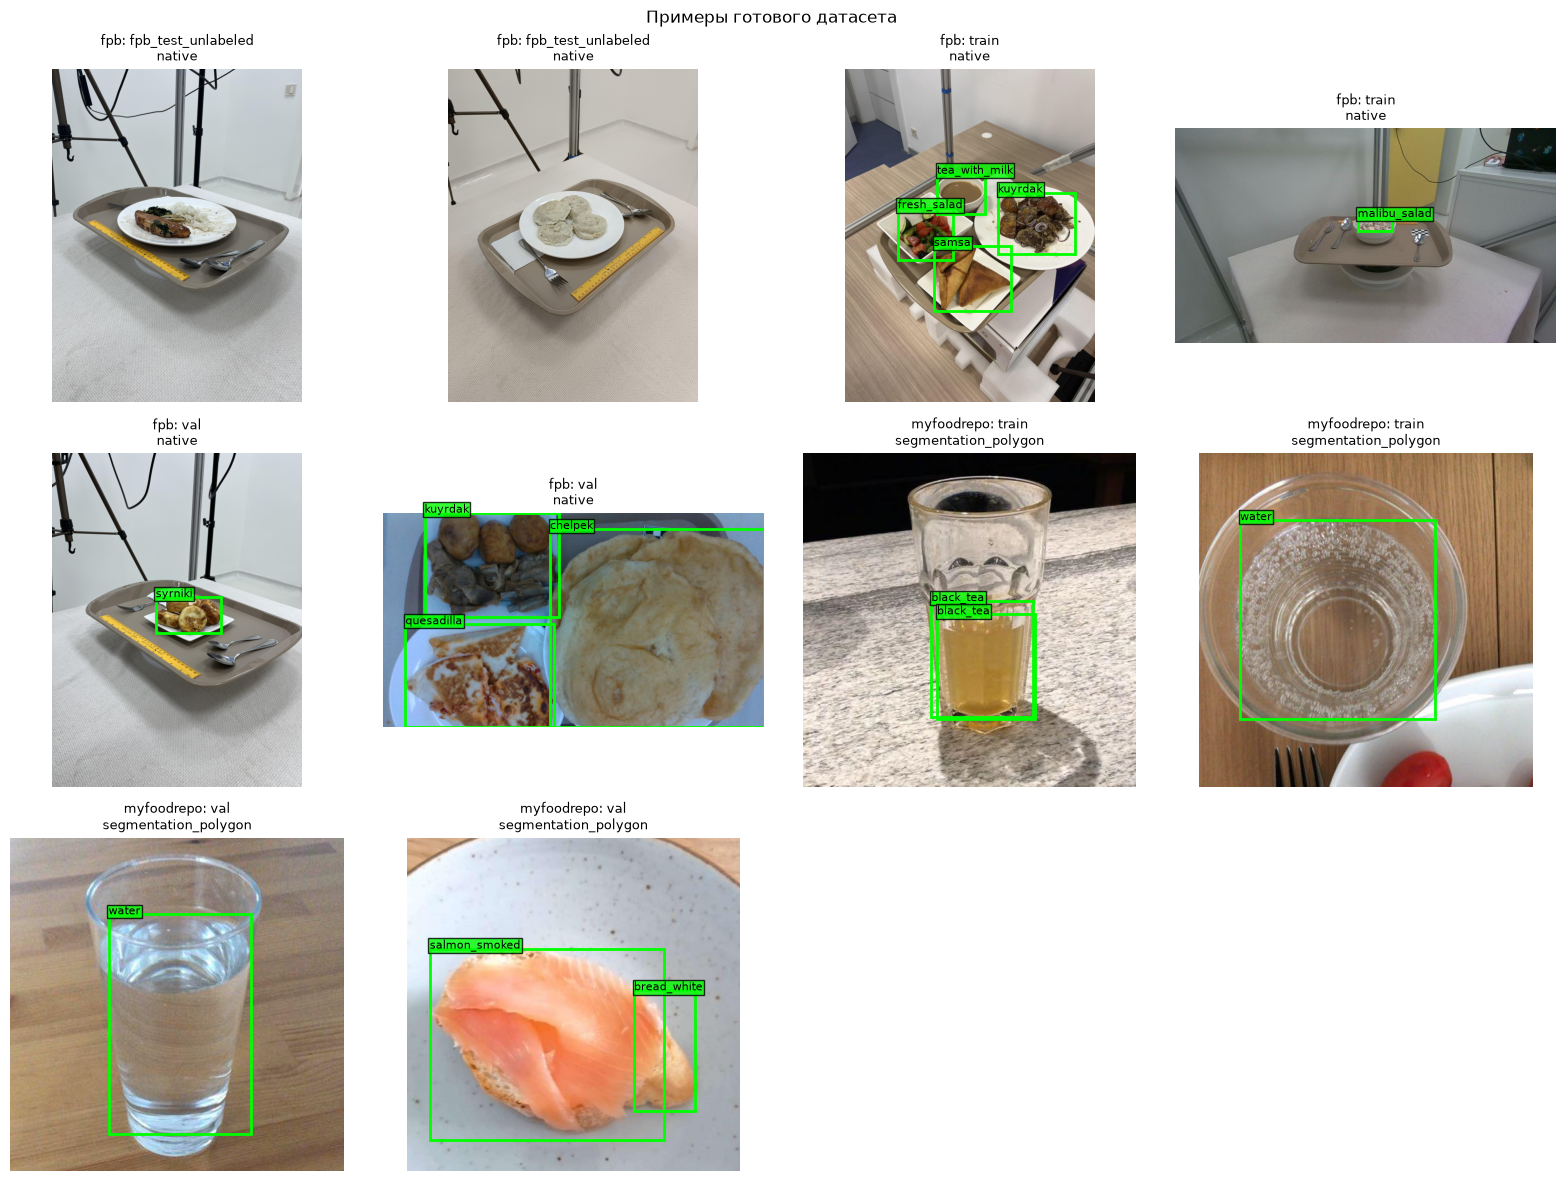

,source,source_id,split,width,height,n_objects
1617,fpb,test/salmon_with_rice_average_RGB_IMG_1984_5_p...,fpb_test_unlabeled,3024,4032,NaN
1471,fpb,test/orama_nan_big_RGB_IMG_20240515_134509_jpg...,fpb_test_unlabeled,3456,4608,NaN
2148,fpb,train/IMG_1114_0_png.rf.1d52f04a130f61930b6777...,train,3024,4032,4.0
6404,fpb,train/malibusalad_big_12Dec_09_ref_Color_png.r...,train,1280,720,1.0
13146,fpb,val/syrniki_big_RGB_IMG_3576_jpeg.rf.c8571a8b6...,val,3024,4032,1.0
11759,fpb,val/set1_big_03Feb_01_Color_png.rf.c8d5301d6d9...,val,1920,1080,3.0
45904,myfoodrepo,train/25971,train,480,480,2.0
61709,myfoodrepo,train/85606,train,482,482,1.0
67119,myfoodrepo,val/153193,val,401,400,1.0
67258,myfoodrepo,val/165460,val,781,781,2.0


In [3]:
sample = images.groupby(["source", "split"], group_keys=False).sample(frac=1, random_state=SEED).groupby(["source", "split"]).head(2)
fig = dp.show_records([records[i] for i in sample.record_i], names, output_root=OUTPUT, count=12, title="Примеры готового датасета")
if fig is not None: plt.close(fig)
display(sample[["source", "source_id", "split", "width", "height", "n_objects"]])


## 2. Размеры изображений и рамок

Читаем фактические размеры, цветовой режим и характеристики качества. Для JPEG используются уменьшенное декодирование и миниатюры; резкость и яркость — сравнительные признаки, а не экспертная оценка. Проверяется читаемость файла. Кеш связан с SHA-256 manifest; после ручного изменения фотографий включите `RECOMPUTE_STATS`.

Полный RGB-хеш каждого изображения уже записан при сборке в ноутбуке 02. Здесь он используется для поиска точных копий; перед удалением найденные файлы повторно читаются целиком. Это не повторное хеширование всех фотографий.

In [4]:
if "thumbnails" in globals(): del thumbnails  # Освободить mmap перед обновлением кеша в Windows.
features, thumbnails = eda.scan_images(DATA, OUTPUT, images, workers=WORKERS, overwrite=RECOMPUTE_STATS)
valid_features = features[features.error == ""].copy()
valid_features["aspect"] = valid_features.width / valid_features.height
valid_features["megapixels"] = valid_features.width * valid_features.height / 1e6
print("Ошибок чтения:", int((features.error != "").sum()))
display(valid_features.groupby("source")[["width", "height", "aspect", "megapixels"]].agg(["min", "median", "max"]))
display(valid_features.groupby(["width", "height"]).size().sort_values(ascending=False).head(15).rename("images").to_frame())
display(valid_features.groupby("mode").size().rename("images").to_frame())

EDA: чтение изображений:   0%|          | 0/264 [00:00<?, ?пакет/s]

Ошибок чтения: 0


width               height                  aspect         \
             min  median   max    min  median   max       min median   
source                                                                 
fpb          640  3024.0  4608    360  4032.0  5712  0.563000   0.75   
myfoodrepo   182   480.0  4608    183   480.0  4096  0.461538   1.00   

                     megapixels                        
                 max        min     median        max  
source                                                 
fpb         1.777778   0.230400  12.192768  24.470208  
myfoodrepo  2.390438   0.033306   0.230400  15.925248

,,images
width,height,
401,400,6320
480,480,5514
464,464,5417
3024,4032,5083
392,391,4090
1280,720,2825
1920,1080,2540
1024,1024,2176
479,479,1464


,images
mode,
RGB,67555


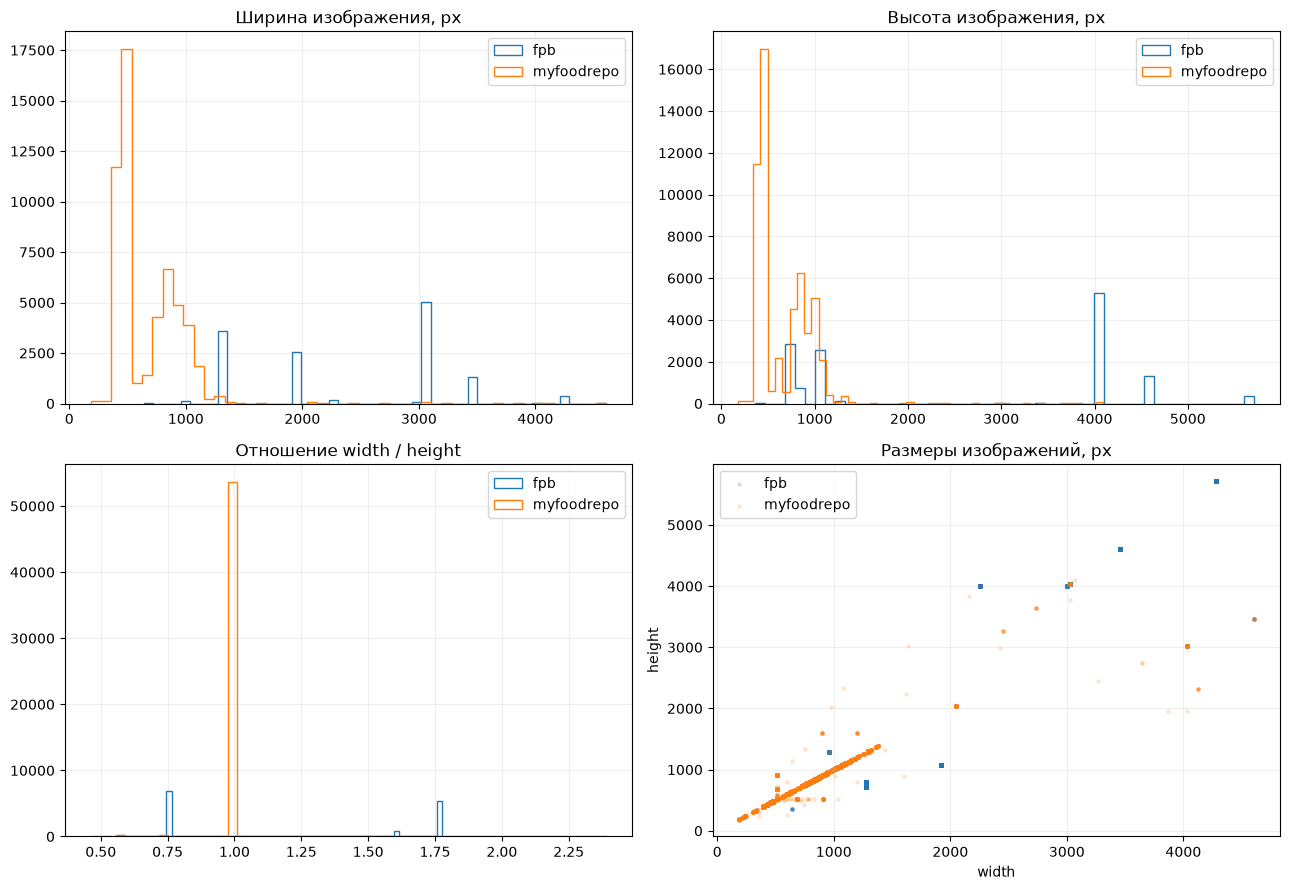

width_px                                                            \
              count        mean         std    min    25%       50%       75%   
source                                                                          
fpb         19812.0  463.897875  309.519383   0.12  167.5  437.5000  649.6675   
myfoodrepo  97553.0  360.744428  214.499081  11.60  212.4  315.5075  456.3000   

                    height_px              ...                 area_norm  \
                max     count        mean  ...    75%      max     count   
source                                     ...                             
fpb         2126.67   19812.0  351.109809  ...  505.0  1792.54   19812.0   
myfoodrepo  3601.68   97553.0  331.687642  ...  424.0  3937.00   97553.0   

                                                                            \
                mean       std           min       25%       50%       75%   
source                                                                       
fpb         0.040877  0.052535  1.461369e-08  0.011219  0.021388  0.050408   
myfoodrepo  0.308993  0.211168  1.218750e-03  0.137845  0.269704  0.441325   

                      
                 max  
source                
fpb         0.652776  
myfoodrepo  0.996253  

[2 rows x 24 columns]

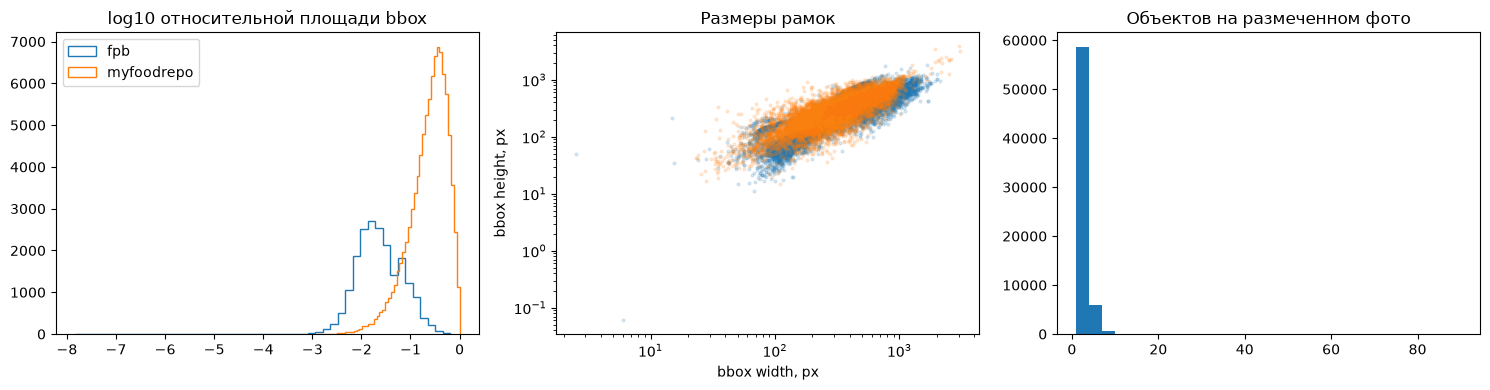

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for source, group in valid_features.groupby("source"):
    axes[0, 0].hist(group.width, bins=50, histtype="step", label=source)
    axes[0, 1].hist(group.height, bins=50, histtype="step", label=source)
    axes[1, 0].hist(group.aspect, bins=60, histtype="step", label=source)
    axes[1, 1].scatter(group.width, group.height, s=5, alpha=0.15, label=source)
for axis, title in zip(axes.flat, ["Ширина изображения, px", "Высота изображения, px", "Отношение width / height", "Размеры изображений, px"]):
    axis.set_title(title); axis.legend(); axis.grid(alpha=0.2)
axes[1, 1].set_xlabel("width"); axes[1, 1].set_ylabel("height")
fig.tight_layout(); plt.show(); plt.close(fig)

boxes = objects.copy()
actual_sizes = features.set_index("record_i")
boxes["width_px"] = boxes.width_norm * boxes.record_i.map(actual_sizes.width)
boxes["height_px"] = boxes.height_norm * boxes.record_i.map(actual_sizes.height)
display(boxes.groupby("source")[["width_px", "height_px", "area_norm"]].describe())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for source, group in boxes.groupby("source"):
    axes[0].hist(np.log10(group.area_norm.clip(lower=1e-12)), bins=50, histtype="step", label=source)
    sampled = group.sample(min(10000, len(group)), random_state=SEED)
    axes[1].scatter(sampled.width_px, sampled.height_px, s=4, alpha=0.15, label=source)
axes[0].set_title("log10 относительной площади bbox"); axes[0].legend()
axes[1].set(xscale="log", yscale="log", xlabel="bbox width, px", ylabel="bbox height, px", title="Размеры рамок")
axes[2].hist(images.loc[images.labeled, "n_objects"], bins=30)
axes[2].set_title("Объектов на размеченном фото")
fig.tight_layout(); plt.show(); plt.close(fig)

## 3. Точные дубликаты и очень похожие изображения

Точные копии группируются по пиксельному SHA-256 из manifest (в хеш включены размеры). Для **кандидатов в похожие** используется независимый dHash миниатюры, близкое соотношение сторон и средняя абсолютная разница RGB. Четыре 16-битные части dHash позволяют искать пары с расстоянием до трёх бит без полного попарного сравнения всех фотографий.

Похожие кадры могут показывать разные ракурсы и порции. Маленькая разница миниатюр или одинаковые классы не доказывают дубликат: эти кандидаты удаляются только при включённом `REMOVE_SIMILAR_IMAGES` после построения плана очистки. Поиск не является исчерпывающим семантическим сравнением: он может пропускать кадры с другим кадрированием, освещением или большим поворотом.

In [6]:
current_manifest_hash = hashlib.sha256((OUTPUT / "manifest.jsonl").read_bytes()).hexdigest()
if current_manifest_hash != MANIFEST_HASH or images.key.tolist() != features.key.tolist():
    raise RuntimeError("Сборка изменилась: запустите ноутбук с начала, включая чтение характеристик.")

exact_groups = images.groupby("pixel_sha256").filter(lambda group: len(group) > 1)
print("Групп точных копий по manifest:", exact_groups.pixel_sha256.nunique())
print("Избыточных точных копий:", len(exact_groups) - exact_groups.pixel_sha256.nunique())

pair_params = {"manifest": MANIFEST_HASH, "hamming": MAX_DHASH_DISTANCE, "mae": MAX_RGB_MAE,
               "aspect": ASPECT_TOLERANCE, "method": 1}
pair_cache = DATA / "metadata" / (OUTPUT.name + ".eda_pairs.json")
cached = dp.read_json(pair_cache) if pair_cache.exists() and not RECOMPUTE_STATS else {}
if cached.get("parameters") == pair_params:
    pairs = pd.DataFrame(cached["pairs"], columns=["a", "b", "hamming", "rgb_mae"])
    print("Использован кеш похожих пар.")
else:
    pairs = eda.similar_pairs(features, thumbnails, hamming=MAX_DHASH_DISTANCE,
                            mae=MAX_RGB_MAE, aspect_tolerance=ASPECT_TOLERANCE)
    dp.dump_json(pair_cache, {"parameters": pair_params, "pairs": pairs.to_dict("records")})
if len(pairs):
    by_i = images.set_index("record_i")
    pairs["exact_hash"] = pairs.a.map(by_i.pixel_sha256) == pairs.b.map(by_i.pixel_sha256)
    pairs["cross_split"] = pairs.a.map(by_i.split) != pairs.b.map(by_i.split)
    def class_set(i):
        return None if records[i]["objects"] is None else tuple(sorted(o["class_id"] for o in records[i]["objects"]))
    pairs["same_classes"] = [class_set(a) == class_set(b) if class_set(a) is not None and class_set(b) is not None else None
                             for a, b in zip(pairs.a, pairs.b)]
    print("Кандидатов в похожие пары:", int((~pairs.exact_hash).sum()), "; между выборками:", int(pairs.cross_split.sum()))
    display(pairs.sort_values(["rgb_mae", "hamming"]).head(20))
else:
    print("Похожих пар по выбранным порогам не найдено.")


Групп точных копий по manifest: 0
Избыточных точных копий: 0


EDA: похожие изображения:   0%|          | 0/67555 [00:00<?, ?фото/s]

Похожих пар по выбранным порогам не найдено.


In [7]:
if len(pairs):
    for number, pair in enumerate(pairs.sort_values(["rgb_mae", "hamming"]).head(10).itertuples(), start=1):
        print(f"Пара {number}: dHash={pair.hamming}, RGB MAE={pair.rgb_mae:.5f}, разные выборки={pair.cross_split}")
        selected = [records[pair.a], records[pair.b]]
        display(pd.DataFrame([{k: row[k] for k in ["source", "source_id", "split", "image"]} for row in selected]))
        fig = dp.show_records(selected, names, output_root=OUTPUT, count=2, title=f"Похожая пара {number} — до применения очистки")
        if fig is not None: plt.close(fig)

## 4. Удаление точных и похожих изображений

`REMOVE_SIMILAR_IMAGES = True` включает очистку по всем трём условиям одновременно: `MAX_DHASH_DISTANCE`, `MAX_RGB_MAE` и `ASPECT_TOLERANCE`. Точные пиксельные копии также включаются в этот режим.

Перед удалением показано число исключаемых изображений и таблица **сохраняемая запись → удаляемая запись**. Сначала сохраняется запись **с разметкой**: при совпадении с неразмеченным test удаляется запись без меток. Среди размеченных записей приоритет: `test` → `val` → `train`, затем источник и исходный ID. Для двух неразмеченных записей используется приоритет выборки и исходный ID. Каждая удаляемая запись должна напрямую соответствовать порогам относительно остающейся записи. Сходство A–B и B–C само по себе не позволяет удалить C при сохранении A, если A–C не соответствует порогам.

В режиме похожих изображений отбор определяется картинками: различия классов или рамок не блокируют удаление; признак `same_classes` вынесен в план. При выборе только точных копий сохраняется прежнее поведение: конфликтующие аннотации остаются для отдельной проверки. Статистические выбросы автоматически не удаляются.

Перед изменением файлов выбранные пары повторно проверяются по изображениям. Очистка обновляет `images/`, `labels/`, manifest, списки выборок, аудит `excluded_records.json` и контрольную сумму сборки. Для похожих кадров в аудите записываются причина `similar_image`, сохраняемый ID, расстояния и пороги; для точных — `pixel_duplicate`. Исходники в `data/raw/` сохраняются. При ошибке проверки изменения откатываются.

Если пороги или manifest изменились после поиска пар, очистка останавливается: нужно повторить поиск, а после изменения состава сборки — запустить ноутбук с начала. Кеш поиска связан с manifest и порогами. Итоговые распределения ниже рассчитываются уже после очистки.

In [8]:
expected_params = {"manifest": hashlib.sha256((OUTPUT / "manifest.jsonl").read_bytes()).hexdigest(),
                   "hamming": MAX_DHASH_DISTANCE, "mae": MAX_RGB_MAE, "aspect": ASPECT_TOLERANCE, "method": 1}
if pair_params != expected_params:
    raise RuntimeError("Пороги или manifest изменились. Повторите поиск похожих пар перед очисткой.")
cleanup_plan = eda.similar_removal_plan(records, pairs, hamming=MAX_DHASH_DISTANCE,
                                      mae=MAX_RGB_MAE, aspect_tolerance=ASPECT_TOLERANCE)
print("План при включении REMOVE_SIMILAR_IMAGES: удалить", len(cleanup_plan), "изображений")
if len(cleanup_plan):
    display(cleanup_plan.groupby(["reason", "remove_split"]).size().rename("images_to_remove").to_frame())
    display(cleanup_plan.head(20))
    print("Пары с различающимися наборами классов:", int((cleanup_plan.same_classes == False).sum()))


План при включении REMOVE_SIMILAR_IMAGES: удалить 0 изображений


In [9]:
if REMOVE_SIMILAR_IMAGES:
    if pair_params != {"manifest": hashlib.sha256((OUTPUT / "manifest.jsonl").read_bytes()).hexdigest(),
                       "hamming": MAX_DHASH_DISTANCE, "mae": MAX_RGB_MAE, "aspect": ASPECT_TOLERANCE, "method": 1}:
        raise RuntimeError("Пороги или manifest изменились. Повторите поиск пар перед удалением.")
    cleanup = eda.remove_similar_images(DATA, OUTPUT, pairs, manifest_hash=pair_params["manifest"],
                                        hamming=MAX_DHASH_DISTANCE, mae=MAX_RGB_MAE,
                                        aspect_tolerance=ASPECT_TOLERANCE)
else:
    cleanup = {"removed": 0, "note": "Удаление отключено параметрами."}
print(json.dumps(cleanup, ensure_ascii=False, indent=2))
records, images, objects, names = eda.load_export(OUTPUT)
print("Изображений после проверки:", len(images))

EDA: проверка удаляемых пар: 0пара [00:00, ?пара/s]

{
  "removed": 0,
  "by_reason": {}
}
Изображений после проверки: 67555


## 7. Распределение классов во всём датасете и по выборкам

Считаем отдельно **объекты** и **изображения с классом**: несколько объектов одного класса на фото увеличивают первый счётчик, а второй — только на единицу. Общие частоты относятся к размеченной части датасета. Для test без меток выводим `NaN`/«неизвестно», а не нули.

В переменных `distribution` и `class_table` доступны все 417 классов, включая отсутствующие в отдельной размеченной выборке.

In [10]:
distribution = eda.class_distribution(records, names)
object_counts = distribution.pivot(index=["class_id", "class"], columns="split", values="objects")
image_counts = distribution.pivot(index=["class_id", "class"], columns="split", values="images")
class_table = object_counts.add_prefix("objects_").join(image_counts.add_prefix("images_")).reset_index()
display(class_table.sort_values("objects_all", ascending=False))
coverage = []
for split in ["all", "train", "val", "test"]:
    part = distribution[distribution.split == split]
    known = part.objects.notna().any()
    coverage.append({"split": split, "objects": int(part.objects.sum()) if known else None,
                     "classes_present": int((part.objects > 0).sum()) if known else None,
                     "classes_missing": int((part.objects == 0).sum()) if known else None})
display(pd.DataFrame(coverage))
missing_valid = class_table[class_table.objects_val == 0][["class_id", "class", "objects_train"]]
print("Нет примеров в valid:", len(missing_valid)); display(missing_valid)
positive = class_table.loc[class_table.objects_all > 0, "objects_all"]
print("Отношение самого частого класса к самому редкому:", round(positive.max() / positive.min(), 2))

split,class_id,class,objects_all,objects_test,objects_train,objects_val,images_all,images_test,images_train,images_val
135,135,water,5765.0,NaN,5641.0,124.0,4527.0,NaN,4405.0,122.0
343,343,salad_leaf_salad_green,2832.0,NaN,2770.0,62.0,2805.0,NaN,2743.0,62.0
160,160,tomato,2722.0,NaN,2662.0,60.0,2682.0,NaN,2622.0,60.0
364,364,bread_white,2609.0,NaN,2570.0,39.0,2526.0,NaN,2487.0,39.0
22,22,butter,2329.0,NaN,2288.0,41.0,2258.0,NaN,2217.0,41.0
...,...,...,...,...,...,...,...,...,...,...
259,259,cake_lemon,55.0,NaN,55.0,0.0,55.0,NaN,55.0,0.0
197,197,damson_plum,55.0,NaN,54.0,1.0,55.0,NaN,54.0,1.0
62,62,kazy,53.0,NaN,53.0,0.0,37.0,NaN,37.0,0.0
47,47,fish_soup,43.0,NaN,43.0,0.0,43.0,NaN,43.0,0.0


,split,objects,classes_present,classes_missing
0,all,117365.0,417.0,0.0
1,train,109721.0,417.0,0.0
2,val,7644.0,376.0,41.0
3,test,NaN,NaN,NaN


Нет примеров в valid: 41


split,class_id,class,objects_train
20,20,bun,151.0
27,27,cheburek,130.0
34,34,ciabatta,127.0
40,40,dapanji,68.0
47,47,fish_soup,43.0
62,62,kazy,53.0
69,69,koktal,86.0
71,71,kurt,152.0
76,76,lime,59.0
85,85,napoleon,79.0


Отношение самого частого класса к самому редкому: 160.14


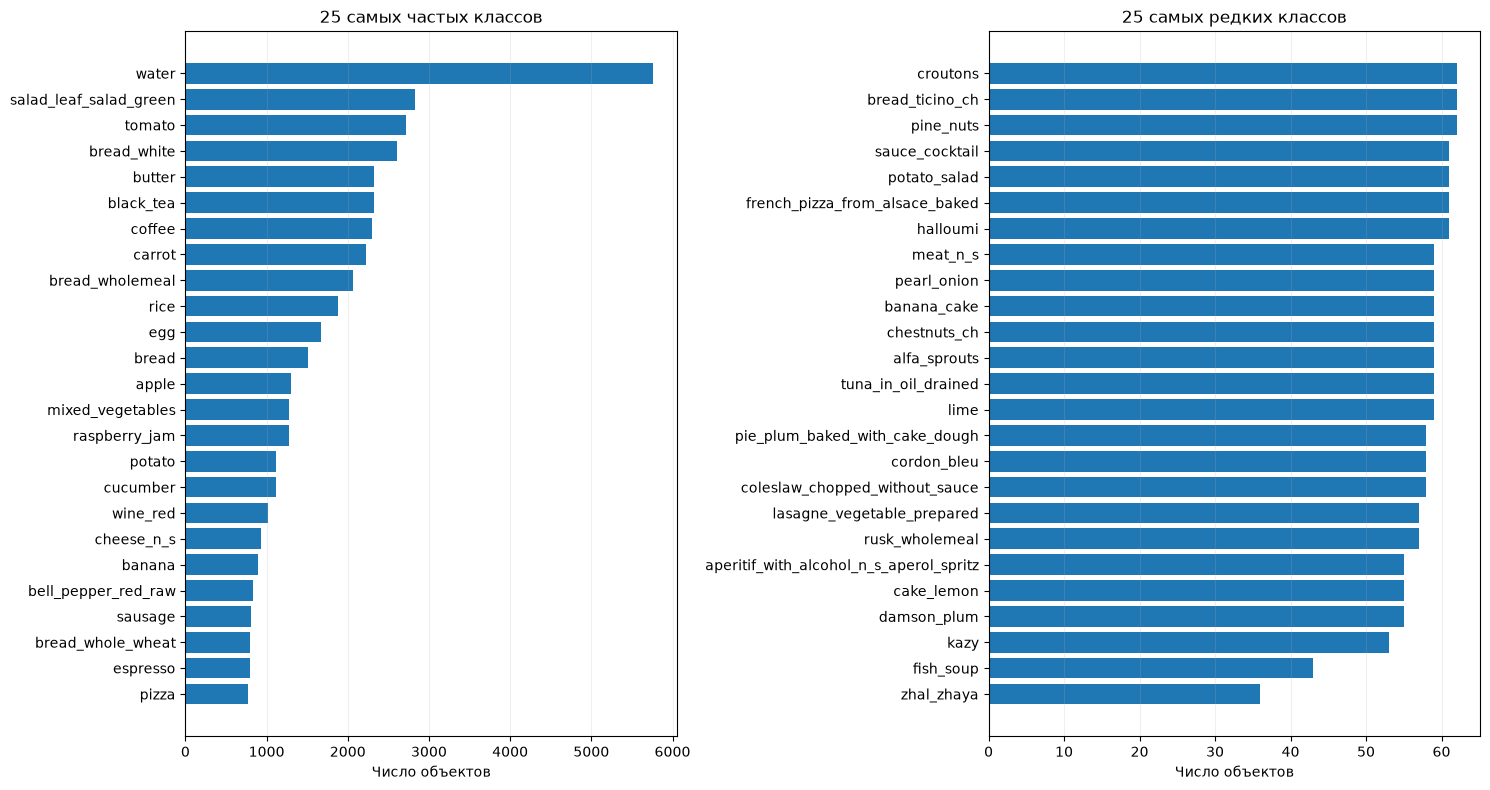

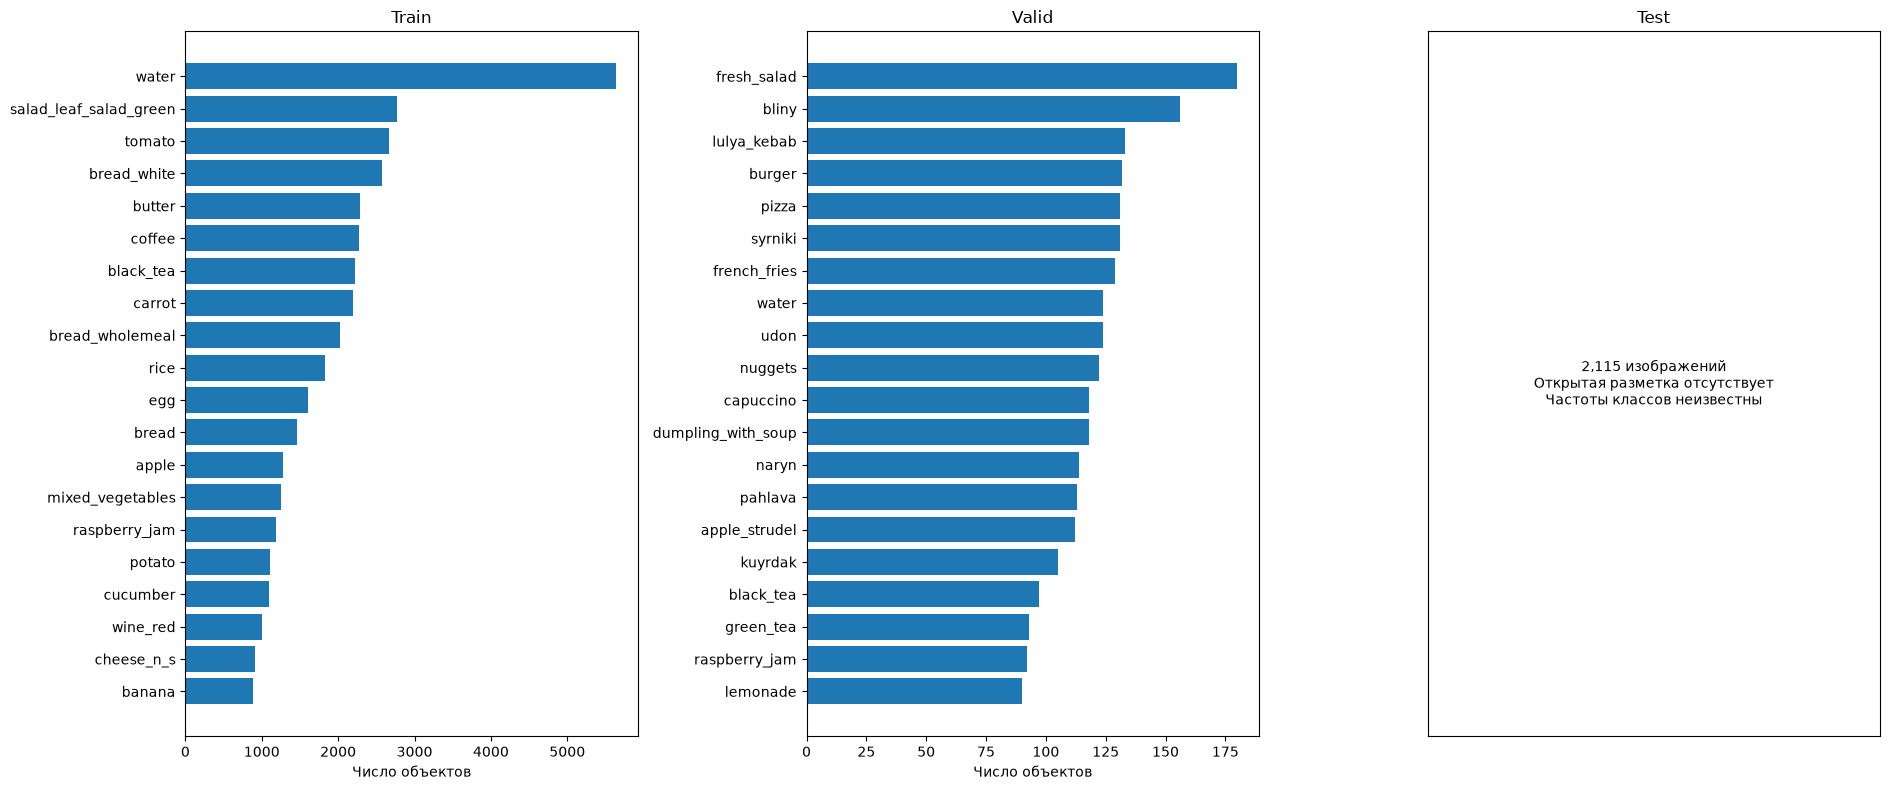

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for axis, frame, title in [(axes[0], class_table.nlargest(25, "objects_all"), "25 самых частых классов"),
                           (axes[1], class_table.nsmallest(25, "objects_all"), "25 самых редких классов")]:
    frame = frame.sort_values("objects_all")
    axis.barh(frame["class"], frame.objects_all)
    axis.set(title=title, xlabel="Число объектов"); axis.grid(axis="x", alpha=0.2)
fig.tight_layout(); plt.show(); plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(19, 8))
for axis, split, title in zip(axes, ["train", "val", "test"], ["Train", "Valid", "Test"]):
    part = distribution[distribution.split == split]
    if part.objects.notna().any():
        top = part.nlargest(20, "objects").sort_values("objects")
        axis.barh(top["class"], top.objects); axis.set_xlabel("Число объектов")
    else:
        count = int(images.split.isin(["test", "fpb_test_unlabeled"]).sum())
        axis.text(0.5, 0.5, f"{count:,} изображений\nОткрытая разметка отсутствует\nЧастоты классов неизвестны", ha="center", va="center", transform=axis.transAxes)
        axis.set_xticks([]); axis.set_yticks([])
    axis.set_title(title)
fig.tight_layout(); plt.show(); plt.close(fig)